# 5. Ajuste de hiperparámetros y diagnóstico (LightGBM)



In [1]:
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from lightgbm import LGBMClassifier, early_stopping
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate, learning_curve

import sys
from pathlib import Path

PROJECT_PATH = Path("..").resolve()
DATA_PATH = PROJECT_PATH / "data"
FIGURES_PATH = PROJECT_PATH / "figures"
sys.path.append(str(PROJECT_PATH))
RANDOM_STATE = 42

warnings.filterwarnings("ignore")
from predictor import TARGET, CATEGORICAL_FEATURES, engineer_features, encode_categories

optuna.logging.set_verbosity(optuna.logging.WARNING)

## 5.1 Datos de train y folds

In [2]:
train_reservations = pd.read_csv(DATA_PATH / "train.csv")
y_train = train_reservations[TARGET]
X_train = engineer_features(train_reservations)
train_categories = {column: sorted(X_train[column].unique()) for column in CATEGORICAL_FEATURES}
X_train_category = encode_categories(X_train, train_categories)
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 5.2 Búsqueda bayesiana con Optuna (TPE)


In [3]:
N_TRIALS = 30
LEARNING_RATE = 0.05
MAX_ESTIMATORS = 3000


def cross_validate_lightgbm(hyperparameters):
    fold_roc_auc, fold_best_iterations = [], []
    for train_index, validation_index in stratified_kfold.split(X_train_category, y_train):
        model = LGBMClassifier(learning_rate=LEARNING_RATE, n_estimators=MAX_ESTIMATORS, subsample_freq=1,
                               random_state=RANDOM_STATE, verbose=-1, **hyperparameters)
        model.fit(X_train_category.iloc[train_index], y_train.iloc[train_index],
                  eval_set=[(X_train_category.iloc[validation_index], y_train.iloc[validation_index])],
                  eval_metric="auc", callbacks=[early_stopping(100, verbose=False)])
        validation_probabilities = model.predict_proba(X_train_category.iloc[validation_index])[:, 1]
        fold_roc_auc.append(roc_auc_score(y_train.iloc[validation_index], validation_probabilities))
        fold_best_iterations.append(model.best_iteration_)
    return np.mean(fold_roc_auc), int(np.mean(fold_best_iterations))


def objective(trial):
    hyperparameters = {
        "num_leaves": trial.suggest_int("num_leaves", 31, 511, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 1, 60, log=True),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 0.9),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        "cat_smooth": trial.suggest_float("cat_smooth", 1, 50, log=True),
        "cat_l2": trial.suggest_float("cat_l2", 1, 30, log=True),
        "min_data_per_group": trial.suggest_int("min_data_per_group", 5, 100, log=True),
        "max_cat_threshold": trial.suggest_int("max_cat_threshold", 16, 128, log=True),
    }
    mean_roc_auc, mean_best_iteration = cross_validate_lightgbm(hyperparameters)
    trial.set_user_attr("n_estimators", mean_best_iteration)
    return mean_roc_auc


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=N_TRIALS)
print(f"Mejor ROC-AUC CV: {study.best_value:.4f}")
study.best_params

Mejor ROC-AUC CV: 0.9614


{'num_leaves': 265,
 'min_child_samples': 1,
 'colsample_bytree': 0.780116197700814,
 'subsample': 0.8397471130376833,
 'reg_lambda': 0.008798051410253282,
 'cat_smooth': 8.903078430688453,
 'cat_l2': 4.127009591505797,
 'min_data_per_group': 12,
 'max_cat_threshold': 57}

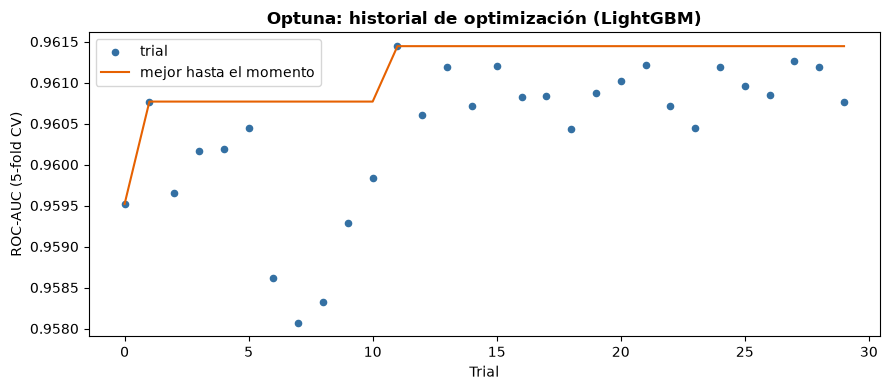

In [4]:
trials_history = study.trials_dataframe()
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(trials_history["number"], trials_history["value"], color="#3470a3", s=20, label="trial")
ax.plot(trials_history["number"], trials_history["value"].cummax(), color="#e66101", label="mejor hasta el momento")
ax.set_xlabel("Trial")
ax.set_ylabel("ROC-AUC (5-fold CV)")
ax.set_title("Optuna: historial de optimización (LightGBM)", fontweight="bold")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_PATH / "10_optuna_history.png", dpi=300)
plt.show()

## 5.3 Curva de validación: número de árboles
Early stopping optimiza ROC-AUC; la competencia mide balanced accuracy, así que se elige el número de árboles con BA (umbral óptimo por punto).

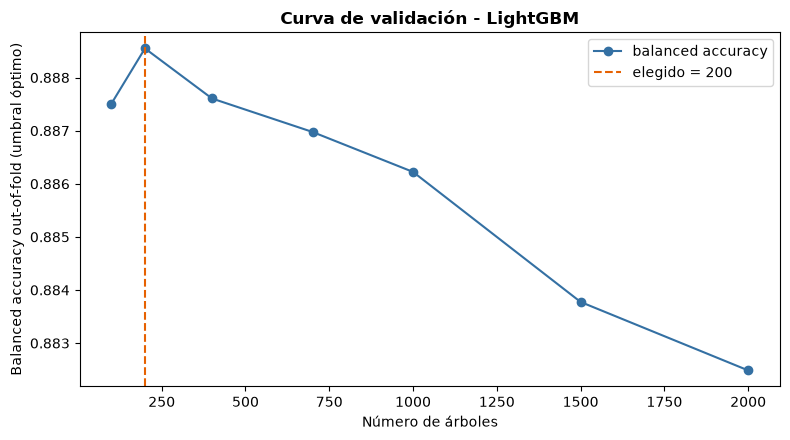

,roc_auc,best_balanced_accuracy
n_estimators,,
100,0.9599,0.8875
200,0.9615,0.8885
400,0.9617,0.8876
700,0.9609,0.8870
1000,0.9597,0.8862
1500,0.9578,0.8838
2000,0.9565,0.8825


In [5]:
N_ESTIMATORS_GRID = [100, 200, 400, 700, 1000, 1500, 2000]
DECISION_THRESHOLDS = np.round(np.arange(0.20, 0.801, 0.01), 2)

out_of_fold_by_trees = {n_estimators: np.zeros(len(y_train)) for n_estimators in N_ESTIMATORS_GRID}
for train_index, validation_index in stratified_kfold.split(X_train_category, y_train):
    model = LGBMClassifier(learning_rate=LEARNING_RATE, n_estimators=max(N_ESTIMATORS_GRID), subsample_freq=1,
                           random_state=RANDOM_STATE, verbose=-1, **study.best_params)
    model.fit(X_train_category.iloc[train_index], y_train.iloc[train_index])
    for n_estimators in N_ESTIMATORS_GRID:
        out_of_fold_by_trees[n_estimators][validation_index] = model.predict_proba(
            X_train_category.iloc[validation_index], num_iteration=n_estimators)[:, 1]

trees_validation_curve = pd.DataFrame([
    {"n_estimators": n_estimators,
     "roc_auc": roc_auc_score(y_train, probabilities),
     "best_balanced_accuracy": max(balanced_accuracy_score(y_train, probabilities >= threshold) for threshold in DECISION_THRESHOLDS)}
    for n_estimators, probabilities in out_of_fold_by_trees.items()
]).set_index("n_estimators")
best_n_estimators = int(trees_validation_curve["best_balanced_accuracy"].idxmax())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(trees_validation_curve.index, trees_validation_curve["best_balanced_accuracy"], marker="o", color="#3470a3", label="balanced accuracy")
ax.axvline(best_n_estimators, color="#e66101", linestyle="--", label=f"elegido = {best_n_estimators}")
ax.set_xlabel("Número de árboles")
ax.set_ylabel("Balanced accuracy out-of-fold (umbral óptimo)")
ax.set_title("Curva de validación - LightGBM", fontweight="bold")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_PATH / "11_validation_curve_n_estimators.png", dpi=300)
plt.show()
trees_validation_curve.round(4)

## 5.4 Hiperparámetros finales

In [6]:
lightgbm_hyperparameters = {
    **study.best_params,
    "learning_rate": LEARNING_RATE,
    "n_estimators": best_n_estimators,
    "subsample_freq": 1,
}
with open(DATA_PATH / "lightgbm_hyperparameters.json", "w") as file:
    json.dump(lightgbm_hyperparameters, file, indent=2)
lightgbm_hyperparameters

{'num_leaves': 265,
 'min_child_samples': 1,
 'colsample_bytree': 0.780116197700814,
 'subsample': 0.8397471130376833,
 'reg_lambda': 0.008798051410253282,
 'cat_smooth': 8.903078430688453,
 'cat_l2': 4.127009591505797,
 'min_data_per_group': 12,
 'max_cat_threshold': 57,
 'learning_rate': 0.05,
 'n_estimators': 200,
 'subsample_freq': 1}

In [7]:
tuned_lightgbm = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, **lightgbm_hyperparameters)
default_lightgbm = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)
tuning_comparison = {}
for model_name, model in [("default", default_lightgbm), ("tuned", tuned_lightgbm)]:
    fold_scores = cross_validate(model, X_train_category, y_train, cv=stratified_kfold,
                                 scoring=["balanced_accuracy", "roc_auc"], return_train_score=True, n_jobs=-1)
    tuning_comparison[model_name] = {metric: fold_scores[metric].mean() for metric in
                                     ["train_balanced_accuracy", "test_balanced_accuracy", "train_roc_auc", "test_roc_auc"]}
pd.DataFrame(tuning_comparison).round(4)

,default,tuned
train_balanced_accuracy,0.8952,0.9966
test_balanced_accuracy,0.8711,0.8859
train_roc_auc,0.9699,0.9998
test_roc_auc,0.9526,0.9615


## 5.5 Curva de aprendizaje

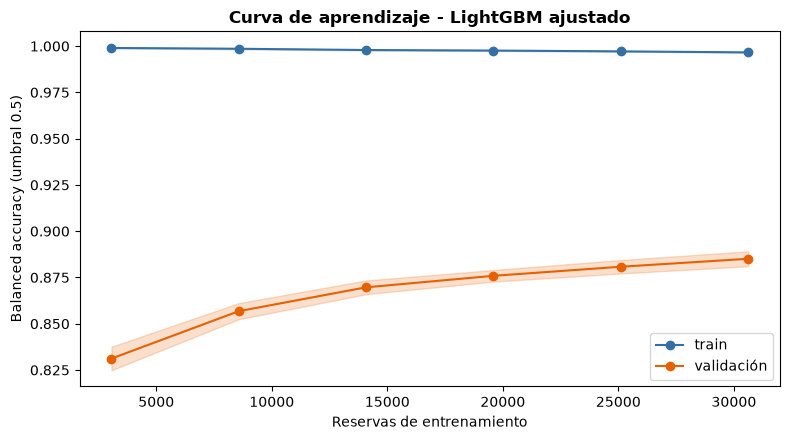

In [8]:
train_sizes, train_scores, validation_scores = learning_curve(
    tuned_lightgbm, X_train_category, y_train, cv=stratified_kfold, scoring="balanced_accuracy",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1,
)
fig, ax = plt.subplots(figsize=(8, 4.5))
for scores, color, label in [(train_scores, "#3470a3", "train"), (validation_scores, "#e66101", "validación")]:
    ax.plot(train_sizes, scores.mean(axis=1), marker="o", color=color, label=label)
    ax.fill_between(train_sizes, scores.mean(axis=1) - scores.std(axis=1), scores.mean(axis=1) + scores.std(axis=1), color=color, alpha=0.2)
ax.set_xlabel("Reservas de entrenamiento")
ax.set_ylabel("Balanced accuracy (umbral 0.5)")
ax.set_title("Curva de aprendizaje - LightGBM ajustado", fontweight="bold")
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES_PATH / "12_learning_curve.png", dpi=300)
plt.show()

## 5.6 Robustez: validación agrupada por reservas duplicadas (Group K-Fold)

In [9]:
duplicate_groups = pd.util.hash_pandas_object(train_reservations.drop(columns=TARGET), index=False)
stratified_group_kfold = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

validation_schemes = {"Stratified K-Fold": (stratified_kfold, None), "Stratified Group K-Fold": (stratified_group_kfold, duplicate_groups)}
scheme_comparison = {}
for scheme_name, (folds, groups) in validation_schemes.items():
    fold_scores = cross_validate(tuned_lightgbm, X_train_category, y_train, groups=groups, cv=folds,
                                 scoring=["balanced_accuracy", "roc_auc"], n_jobs=-1)
    scheme_comparison[scheme_name] = {"balanced_accuracy": fold_scores["test_balanced_accuracy"].mean(),
                                      "roc_auc": fold_scores["test_roc_auc"].mean()}
pd.DataFrame(scheme_comparison).round(4)

,Stratified K-Fold,Stratified Group K-Fold
balanced_accuracy,0.8859,0.8539
roc_auc,0.9615,0.9434


## Conclusiones
- El ajuste mejora la validación respecto de LightGBM por defecto (BA ≈ 0.871 → 0.886, ROC-AUC ≈ 0.953 → 0.962).
- Árboles grandes y `min_child_samples` bajo: el modelo aprovecha reservas muy parecidas o repetidas (BA train ≈ 1).
- La BA es máxima con pocos cientos de árboles; más árboles la bajan levemente.
- Curva de aprendizaje: la validación sigue subiendo con más datos → el modelo final se reentrena con train + test (notebook 7).
- Con Group K-Fold (sin duplicados compartidos) la BA baja a ≈ 0.85: sigue por encima del líder (0.828) aun en el escenario más exigente.